In [ ]:
import os
os.environ['KAGGLE_USERNAME'] = "araiyan3070"
os.environ['KAGGLE_KEY'] = "KGAT_e06836367d80b66be751f7b4be20eb48"

In [ ]:
!kaggle datasets download -d 'ahmedshahriarsakib/usa-real-estate-dataset'

Dataset URL: https://www.kaggle.com/datasets/ahmedshahriarsakib/usa-real-estate-dataset
License(s): other
100% 38.2M/38.2M [00:00<00:00, 55.1MB/s]



In [ ]:
import pandas as pd
df = pd.read_csv('/content/usa-real-estate-dataset.zip')

In [ ]:
df.head()

,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,34632.0,for_sale,65000.0,6.0,2.0,0.05,331151.0,Mayaguez,Puerto Rico,680.0,NaN,NaN


In [ ]:
df.isnull().sum()

,0
brokered_by,4533
status,0
price,1541
bed,481317
bath,511771
acre_lot,325589
street,10866
city,1407
state,8
zip_code,299


In [ ]:
df.shape

(2226382, 12)

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
prev_sold_date,734297
house_size,568484
bath,511771
bed,481317
acre_lot,325589
street,10866
brokered_by,4533
price,1541
city,1407
zip_code,299


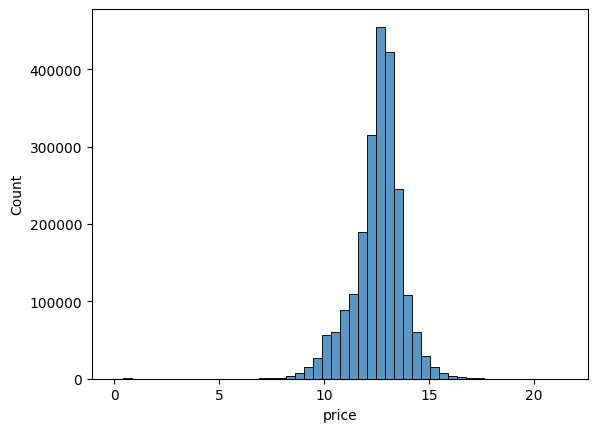

In [ ]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

sns.histplot(np.log1p(df['price']), bins=50)
plt.show()

<Axes: >

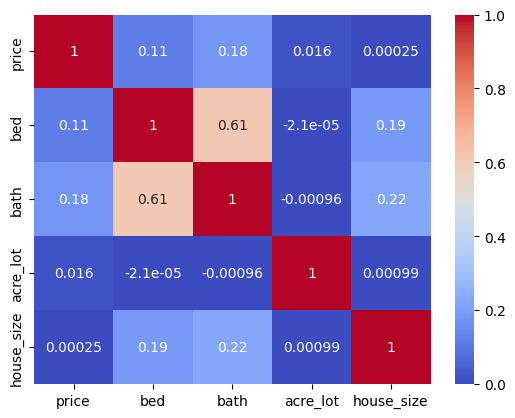

In [ ]:
corr_cols = [
    'price',
    'bed',
    'bath',
    'acre_lot',
    'house_size'
]

sns.heatmap(df[corr_cols].corr(),
            annot=True,
            cmap='coolwarm')

<Axes: xlabel='state'>

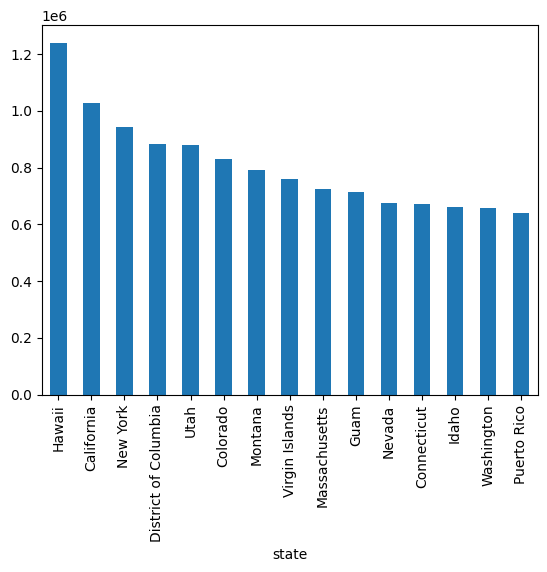

In [ ]:
top_states = df.groupby('state')['price'] \
               .mean() \
               .sort_values(ascending=False)[:15]

top_states.plot(kind='bar')

In [ ]:
df['bed'] = df.groupby('city')['bed'] \
              .transform(lambda x: x.fillna(x.median()))

df['bath'] = df.groupby('city')['bath'] \
               .transform(lambda x: x.fillna(x.median()))

In [ ]:
df['bed'] = df['bed'].fillna(df['bed'].median())
df['bath'] = df['bath'].fillna(df['bath'].median())

In [ ]:
df['house_size'] = (
    df.groupby('city')['house_size']
      .transform(lambda x: x.fillna(x.median()))
)

df['house_size'] = (
    df['house_size']
      .fillna(df['house_size'].median())
)

In [ ]:
df['acre_lot'] = (
    df.groupby('zip_code')['acre_lot']
      .transform(lambda x: x.fillna(x.median()))
)

df['acre_lot'] = (
    df['acre_lot']
      .fillna(df['acre_lot'].median())
)

In [ ]:
df['prev_sold_date'] = pd.to_datetime(
    df['prev_sold_date'],
    errors='coerce'
)

df['has_previous_sale'] = (
    df['prev_sold_date'].notna().astype(int)
)

df['sold_year'] = df['prev_sold_date'].dt.year
df['sold_month'] = df['prev_sold_date'].dt.month

df['sold_year'] = df['sold_year'].fillna(-1)
df['sold_month'] = df['sold_month'].fillna(-1)

In [ ]:
df['years_since_sale'] = (
    2025 - df['sold_year']
)

df['years_since_sale'] = (
    df['years_since_sale']
      .replace(2026, -1)
)

In [ ]:
df['prev_sold_date'] = pd.to_datetime(
    df['prev_sold_date'],
    errors='coerce'
)

df['sold_year'] = df['prev_sold_date'].dt.year
df['sold_month'] = df['prev_sold_date'].dt.month

In [ ]:
df['years_since_sale'] = (
    2025 - df['sold_year']
)

In [ ]:
df['price_per_bed'] = (
    df['price'] /
    (df['bed'] + 1)
)

In [ ]:
df['bath_bed_ratio'] = (
    df['bath'] /
    (df['bed'] + 1)
)

In [ ]:
df['size_per_acre'] = (
    df['house_size'] /
    (df['acre_lot'] + 0.01)
)

In [ ]:
state_price = (
    df.groupby('state')['price']
      .median()
)

df['state_price_median'] = (
    df['state'].map(state_price)
)

In [ ]:
city_price = (
    df.groupby('city')['price']
      .median()
)

df['city_price_median'] = (
    df['city'].map(city_price)
)

In [ ]:
zip_price = (
    df.groupby('zip_code')['price']
      .median()
)

df['zip_price_median'] = (
    df['zip_code'].map(zip_price)
)

In [ ]:
q1 = df['price'].quantile(0.01)
q99 = df['price'].quantile(0.99)

df = df[
    (df['price'] >= q1) &
    (df['price'] <= q99)
]

In [ ]:
cat_cols = [
    'status',
    'city',
    'state',
    'zip_code'
]

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = np.log1p(df['price'])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
from lightgbm import LGBMRegressor
import pandas as pd

model = LGBMRegressor(
    n_estimators=200,
    learning_rate=0.03,
    num_leaves=64,
    max_depth=12,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

X_train_processed = X_train.copy()
X_test_processed = X_test.copy()

for col in cat_cols:
    if col in X_train_processed.columns:

        X_train_processed[col] = X_train_processed[col].astype('category')

        train_categories = X_train_processed[col].cat.categories

        if col in X_test_processed.columns:

            X_test_processed[col] = pd.Categorical(X_test_processed[col], categories=train_categories)

if 'prev_sold_date' in X_train_processed.columns:
    X_train_processed = X_train_processed.drop('prev_sold_date', axis=1)
if 'prev_sold_date' in X_test_processed.columns:
    X_test_processed = X_test_processed.drop('prev_sold_date', axis=1)

model.fit(
    X_train_processed,
    y_train,
    categorical_feature=cat_cols
)

X_train = X_train_processed
X_test = X_test_processed

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.364447 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 24432
[LightGBM] [Info] Number of data points in the train set: 1746660, number of used features: 20
[LightGBM] [Info] Start training from score 12.551136


In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

pred = model.predict(X_test)

pred = np.expm1(pred)
actual = np.expm1(y_test)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        pred
    )
)

r2 = r2_score(
    actual,
    pred
)

print("RMSE:", rmse)
print("R2:", r2)

RMSE: 36394.832136055455
R2: 0.9941010871212235


In [ ]:
new_property = pd.DataFrame({
    'brokered_by':[103378],
    'status':['for_sale'],
    'bed':[4],
    'bath':[3],
    'acre_lot':[0.25],
    'street':[0],
    'city':['Beverly Hills'],
    'state':['California'],
    'zip_code':['90210'],
    'house_size':[2400],
    'sold_year':[2020],
    'sold_month':[5],
    'years_since_sale':[5],
    'has_previous_sale':[1],
    'bath_bed_ratio':[3/(4+1)],
    'size_per_acre':[2400/0.25]
})

new_property['state_price_median'] = new_property['state'].map(state_price)
new_property['city_price_median'] = new_property['city'].map(city_price)
new_property['zip_price_median'] = new_property['zip_code'].map(zip_price)

for col in ['state_price_median', 'city_price_median', 'zip_price_median']:
    if new_property[col].isnull().any():
        new_property[col] = new_property[col].fillna(X_train[col].median())

if 'price_per_bed' not in new_property.columns:
    new_property['price_per_bed'] = X_train['price_per_bed'].median()

for col in cat_cols:
    if col in new_property.columns and col in X_train.columns:
        if not isinstance(X_train[col].dtype, pd.CategoricalDtype):
            X_train[col] = X_train[col].astype('category')
        train_categories = X_train[col].cat.categories
        new_property[col] = pd.Categorical(new_property[col], categories=train_categories)
    elif col in X_train.columns and col not in new_property.columns:
        new_property[col] = pd.Categorical([], categories=X_train[col].cat.categories)

new_property = new_property[X_train.columns]

pred_log_price = model.predict(new_property)

estimated_price = np.expm1(pred_log_price)

print("Estimated Property Value: $", round(estimated_price[0], 2))

Estimated Property Value: $ 411167.75
